# 04 — Clinical evaluation

An accuracy figure means nothing on its own. This notebook establishes **what** the model is
compared against, on **which set**, and with **what uncertainty**.

In [1]:
import json

import pandas as pd

from clinical_triage.config import PATHS

pd.set_option("display.max_colwidth", 130)
results = json.loads((PATHS.reports / "evaluation_results.json").read_text(encoding="utf-8"))
clinical = results["clinical_set"]
# The merged model first: it is the one that is published and served.
shipped = next(n for n in ("dpo-merged", "dpo", "sft", "base") if n in clinical["models"])


def progression(models):
    """One form of the aligned model for the figures: the two are identical."""
    if "dpo-merged" in models and "dpo" in models:
        return {n: v for n, v in models.items() if n != "dpo"}
    return models


print(
    f"clinical set: {clinical['n']} cases - internal test split: {results['internal_set']['n']} cases"
)
print(f"most advanced model evaluated: {shipped}")

clinical set: 60 cases - internal test split: 120 cases
most advanced model evaluated: dpo-merged


## 1. Why the first evaluation measured nothing

An early version of the project labelled the corpus with a keyword rule, then evaluated the
model against those same labels. Re-applying the rule to the evaluation set recovered almost
every label, more than the fine-tuned model managed.

The protocol was therefore not measuring the quality of the triage: it was measuring how well
the model had managed to relearn the rule. And it concluded, without saying so, that the rule
alone was preferable. The two rates that showed it are not reproduced here, because the version
that produced them has left the repository, and a figure no tracked artefact carries has no
business being published.

The current evaluation set is **written by hand**, its labels come from clinical reasoning, and
the rule appears **beside** the model, as a baseline to beat.

In [2]:
cases = [
    json.loads(line)
    for line in (PATHS.data_processed / "clinical_eval.jsonl").open(encoding="utf-8")
]
preview = pd.DataFrame(cases)[["id", "level", "lang", "case_type", "description"]]
preview["description"] = preview["description"].str.slice(0, 95) + "…"
preview.head(6)

,id,level,lang,case_type,description
0,ev01,URGENCE_VITALE,fr,,"Un homme de 67 ans est amené par sa femme. Il serre son poing sur sa poitrine, transpire abonda…"
1,ev02,URGENCE_VITALE,fr,,"Femme de 74 ans : sa fille l'a trouvée ce matin incapable de parler correctement, le coin de la…"
2,ev03,URGENCE_VITALE,en,,"A 5-year-old boy was stung by a wasp fifteen minutes ago. His lips are swelling, he is covered …"
3,ev04,URGENCE_VITALE,fr,,"Patiente de 31 ans, enceinte de 34 semaines, se plaint depuis ce matin de céphalées qui ne cède…"
4,ev05,URGENCE_VITALE,en,,"A 3-month-old infant has been feeding poorly for two days and is now breathing very fast, with …"
5,ev06,URGENCE_VITALE,fr,,"Homme de 45 ans, cirrhotique, a vomi deux fois du sang rouge il y a une heure. Il est très pâle…"


In [3]:
from collections import Counter

print("levels    :", dict(Counter(c["level"] for c in cases)))
print("languages :", dict(Counter(c["lang"] for c in cases)))
print("case types:", dict(Counter(c["case_type"] or "direct_presentation" for c in cases)))

levels    : {'URGENCE_VITALE': 20, 'URGENCE_MODEREE': 20, 'CONSULTATION_DIFFEREE': 20}
languages : {'fr': 32, 'en': 28}
case types: {'direct_presentation': 32, 'falsely_reassuring': 10, 'discordant_vitals': 3, 'negation': 4, 'falsely_alarming': 11}


Nearly half the cases are **atypical presentations**: an emergency that looks benign, a
spectacular symptom with nothing serious behind it, a severe sign explicitly denied, vital signs
that contradict the narrative. Each one carries the clinical reason for its label.

In [4]:
trap = next(c for c in cases if c["case_type"] == "falsely_reassuring")
print(f"[{trap['id']}] expected: {trap['level']}")
print()
print(trap["description"])
print()
print(f"clinical reason: {trap['clinical_note']}")

[ev11] expected: URGENCE_VITALE

Femme de 71 ans, diabétique de longue date, se dit seulement « très fatiguée » depuis deux heures, avec une vague nausée et un essoufflement inhabituel en montant chez elle. Elle insiste sur le fait qu'elle n'a aucune douleur. FC 112, TA 96/60, SpO2 93 %.

clinical reason: Infarctus silencieux du diabétique : l'absence de douleur thoracique est fréquente et trompeuse.


## 2. Four baselines

- **majority class**, what a system that always answers the same thing would give;
- **maximum caution**, always the life-threatening level. That system never undertriages and
  sends everybody to resuscitation: it is there to recall that safety cannot be judged without
  looking at what caution costs;
- **explicit rule**, the one a department can deploy in an afternoon. It is the real baseline:
  if the model does not pass it, the project has no reason to exist;
- **ordinary classifier**, n-grams and a linear separator trained on the same examples, which says
  what fine-tuning adds over ordinary learning.

In [5]:
def table(dataset):
    rows = []
    for name, measures in [*dataset["baselines"].items(), *dataset["models"].items()]:
        low, high = measures["accuracy_ci95"]
        rows.append(
            {
                "system": name,
                "accuracy": round(measures["accuracy"], 3),
                "95% CI": f"[{low:.2f} – {high:.2f}]",
                "undertriage": round(measures["undertriage"], 3),
                "overtriage": round(measures["overtriage"], 3),
                "format compliance": round(measures["format_compliance"], 3),
            }
        )
    return pd.DataFrame(rows)


table(clinical)

,system,accuracy,95% CI,undertriage,overtriage,format compliance
0,majority_class,0.333,[0.23 – 0.46],1.000,0.000,1.000
1,always_critical,0.333,[0.23 – 0.46],0.000,0.667,1.000
2,explicit_rule,0.617,[0.49 – 0.73],0.550,0.017,1.000
3,linear_classifier,0.667,[0.54 – 0.77],0.200,0.200,1.000
4,base,0.167,[0.09 – 0.28],0.525,0.283,0.467
5,sft,0.700,[0.57 – 0.80],0.300,0.100,1.000
6,dpo,0.700,[0.57 – 0.80],0.275,0.117,1.000
7,dpo-merged,0.717,[0.59 – 0.81],0.275,0.100,1.000


Every figure comes with a **confidence interval**, at the 95% level. On a few dozen cases a gap
of three points is not a gap, and publishing accuracy without its interval would suggest
otherwise. The estimator follows the quantity: Wilson on accuracy, exact on undertriage, where
the samples are smallest.

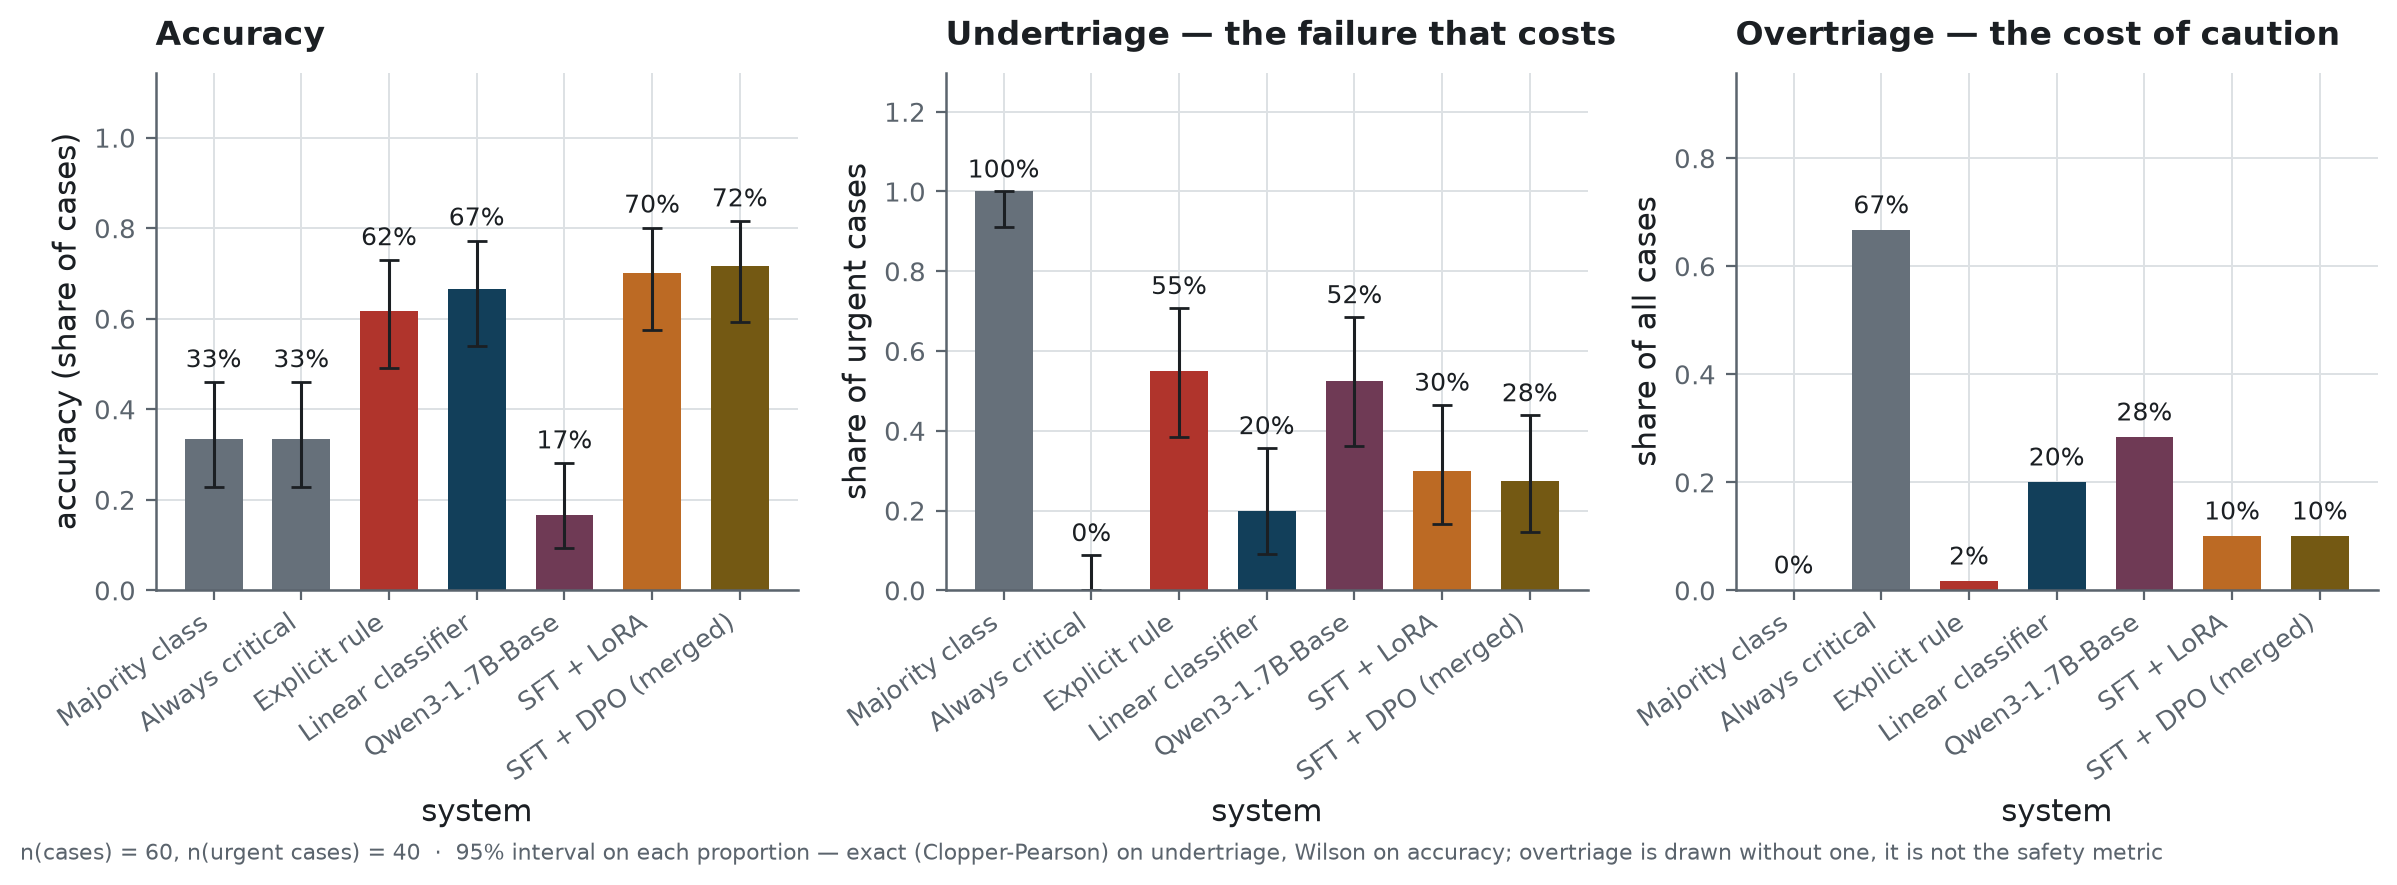

In [6]:
import matplotlib.pyplot as plt
from IPython.display import Image

from clinical_triage.reporting import figures

figures.apply_style()
measures = dict([*clinical["baselines"].items(), *progression(clinical["models"]).items()])
path = figures.systems_comparison(measures, PATHS.figures / "systems_comparison.png")
plt.close("all")
Image(str(path))

## 3. Confusion matrices

The "off-format" column isolates the answers nothing can use. Filing them under a triage class
would distort the reading: that was the case in an earlier version, where the base model appeared
to predict the life-threatening level massively while it was simply producing nothing usable.

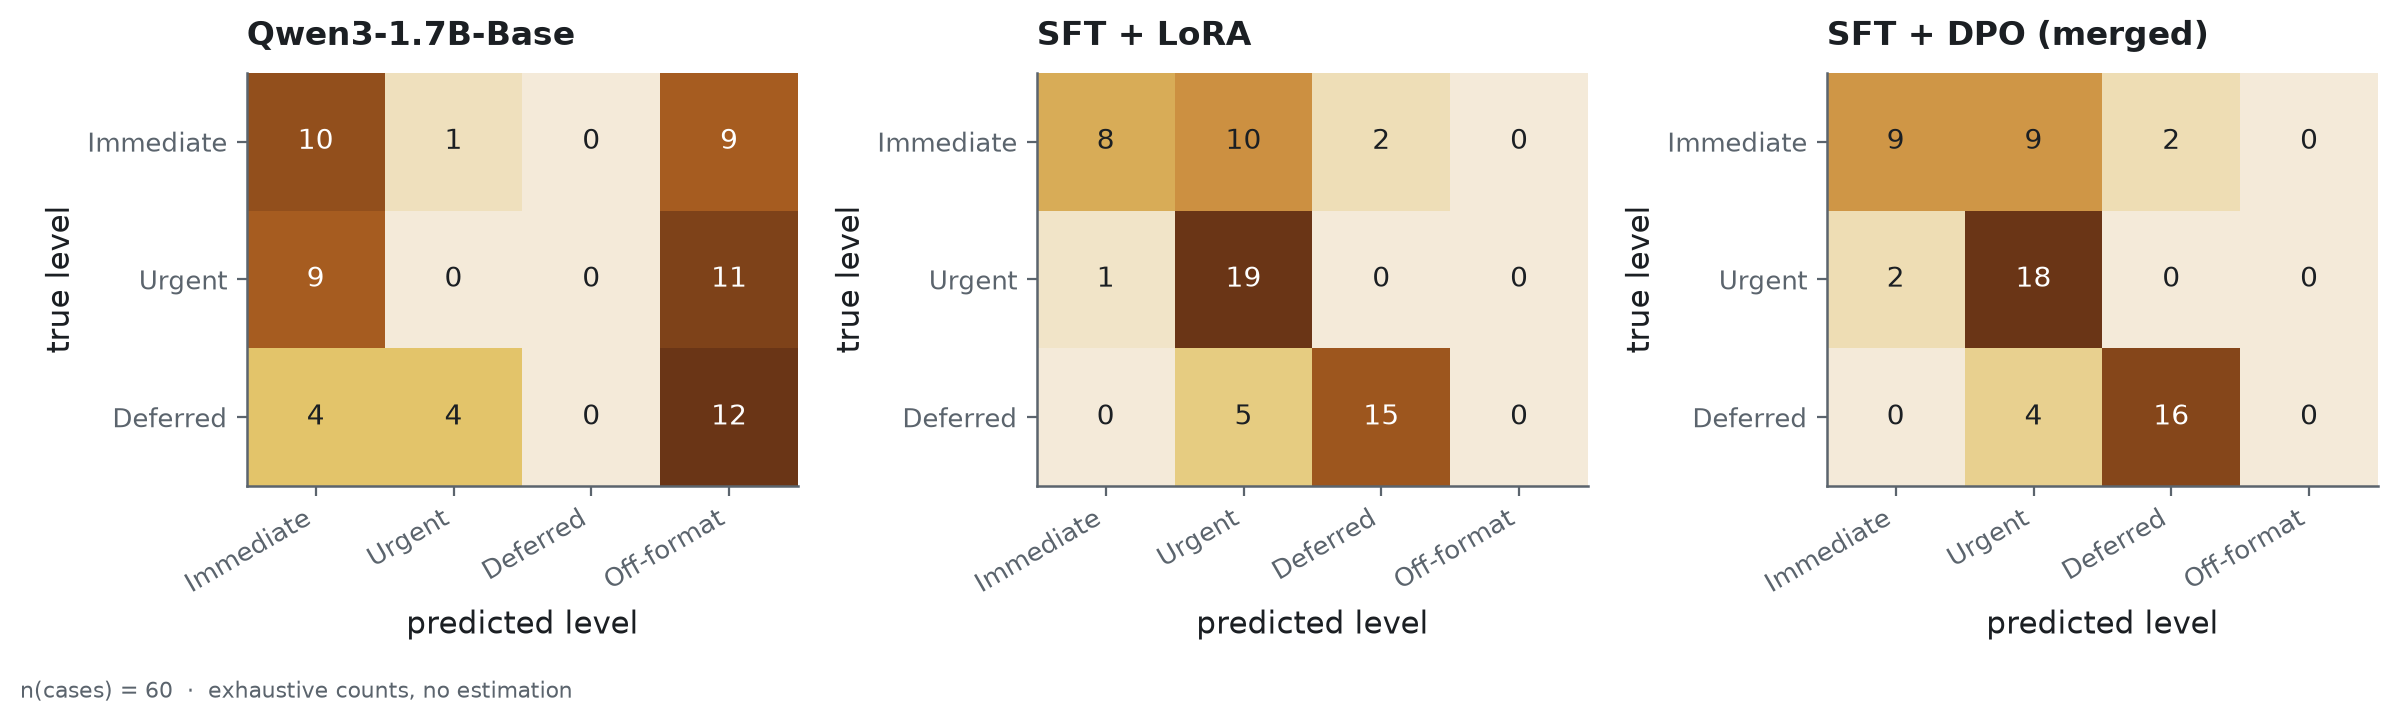

In [7]:
path = figures.confusion_matrices(
    {
        figures.SYSTEM_LABELS.get(name, name): values["confusion"]
        for name, values in progression(clinical["models"]).items()
    },
    PATHS.figures / "confusion_matrices.png",
)
plt.close("all")
Image(str(path))

## 4. What is learnt, and what transfers

The model is also evaluated on the **internal test split**, which comes out of the generator that
wrote the training data. The gap between the two sets is the useful information.

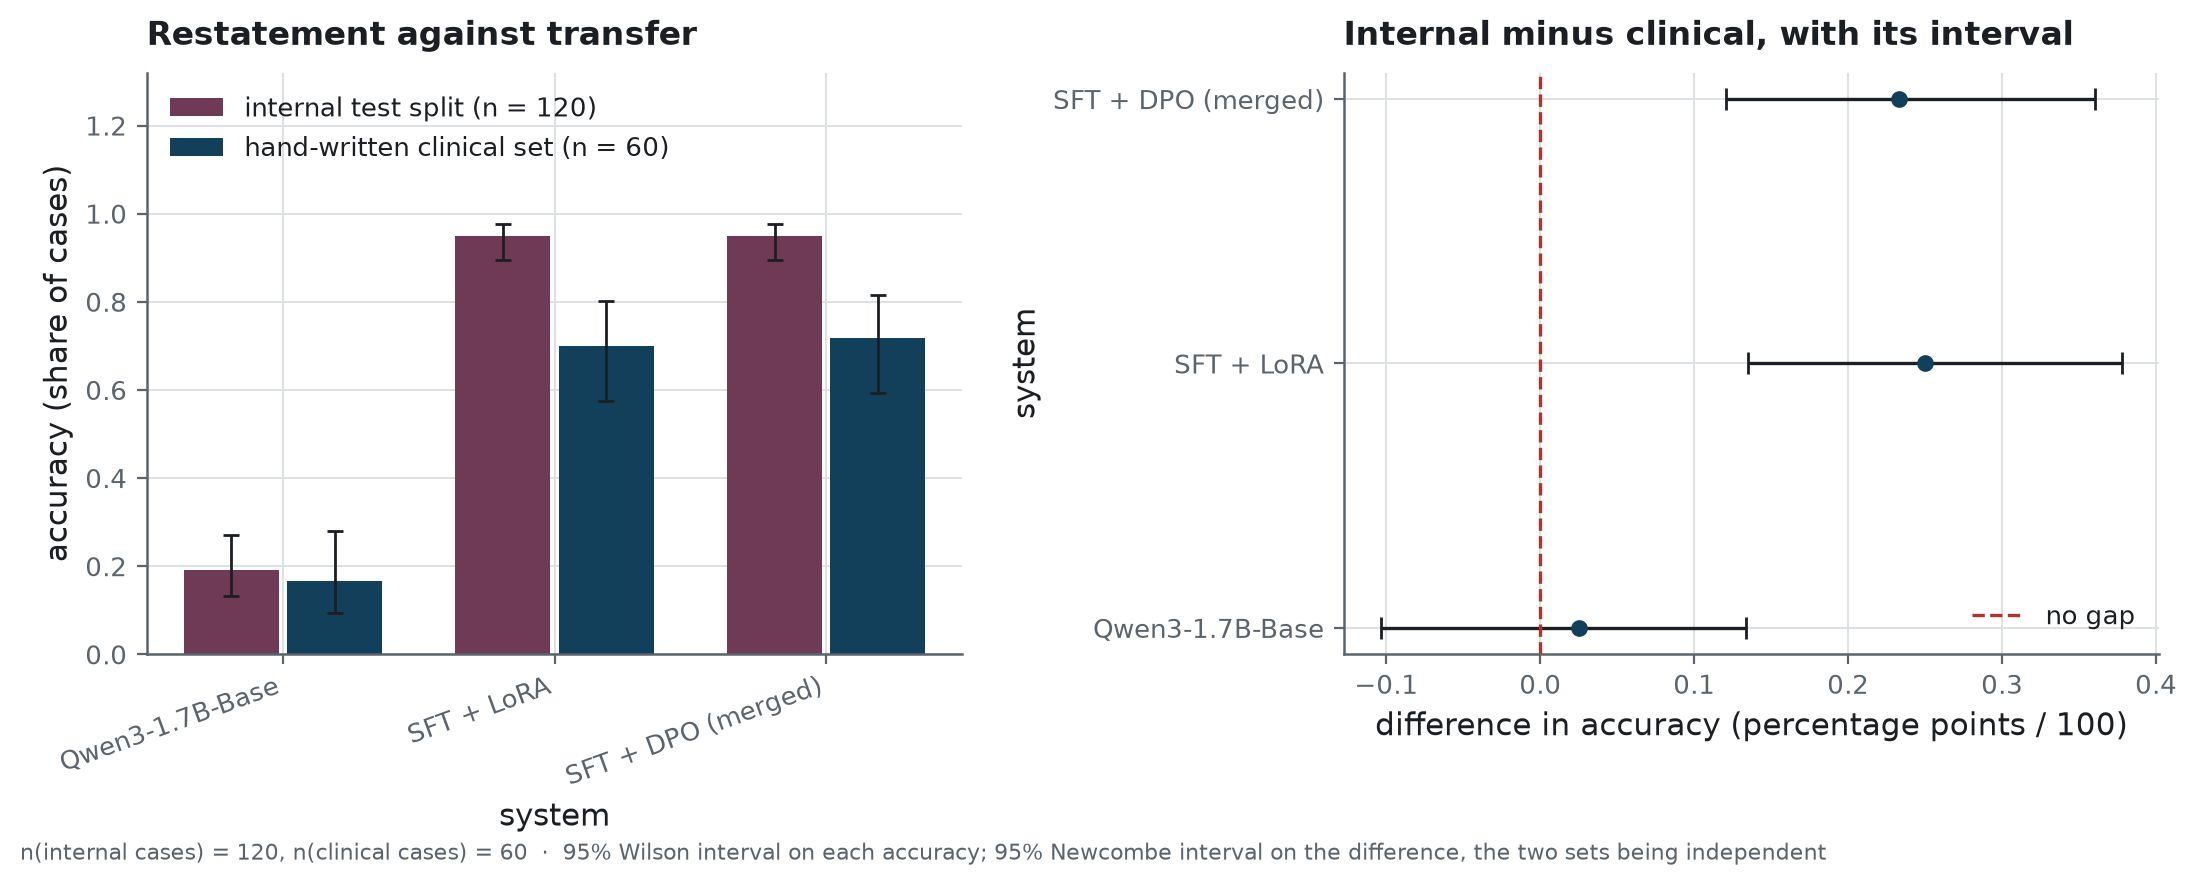

internal split: 0.95 · clinical set: 0.72 · gap: +0.23


In [8]:
if results["internal_set"]["models"]:
    path = figures.recall_versus_transfer(
        progression(results["internal_set"]["models"]),
        progression(clinical["models"]),
        PATHS.figures / "recall_versus_transfer.png",
    )
    plt.close("all")
    display(Image(str(path)))
    internal = results["internal_set"]["models"][shipped]["accuracy"]
    external = clinical["models"][shipped]["accuracy"]
    print(
        f"internal split: {internal:.2f} · clinical set: {external:.2f} · "
        f"gap: {internal - external:+.2f}"
    )

## 5. Performance by kind of case

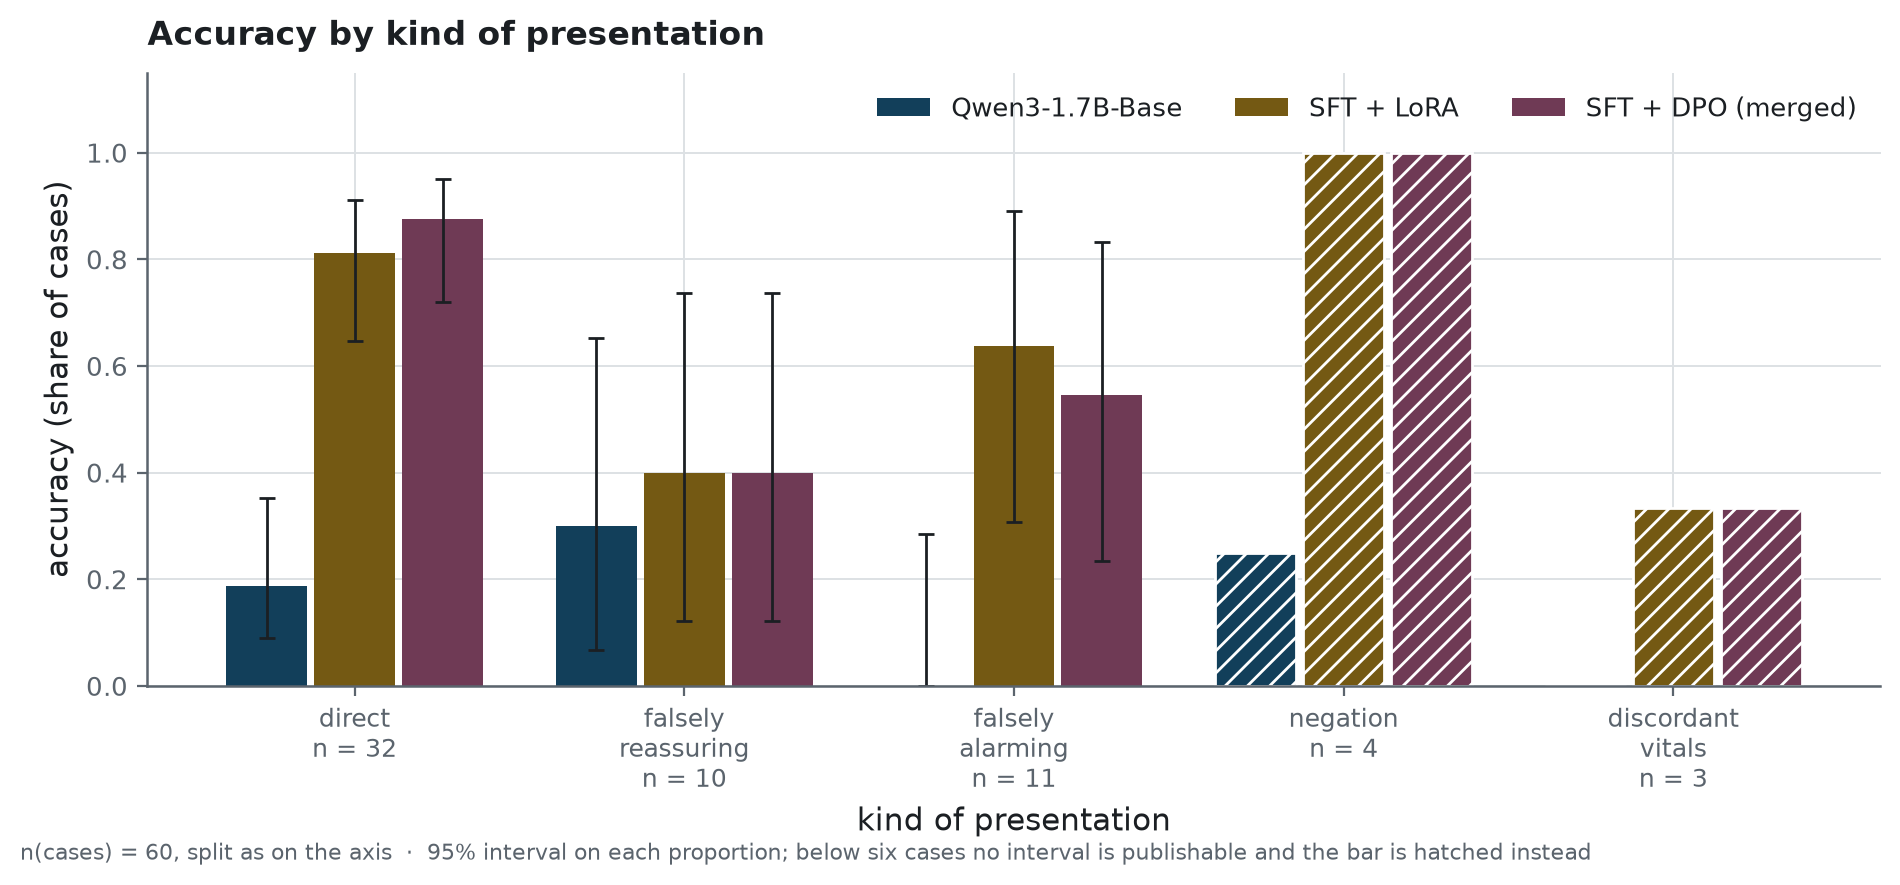

,n,accuracy,undertriage
direct_presentation,32,0.875,0.15
discordant_vitals,3,0.3333,0.6667
falsely_alarming,11,0.5455,0.0
falsely_reassuring,10,0.4,0.6
negation,4,1.0,0.0


In [9]:
path = figures.accuracy_by_case_type(
    {
        figures.SYSTEM_LABELS.get(name, name): values["per_case_type"]
        for name, values in progression(clinical["models"]).items()
    },
    PATHS.figures / "accuracy_by_case_type.png",
)
plt.close("all")
display(Image(str(path)))

pd.DataFrame(clinical["models"][shipped]["per_case_type"]).T[["n", "accuracy", "undertriage"]]

In [10]:
pd.DataFrame(clinical["models"][shipped]["per_language"]).T[["n", "accuracy", "undertriage"]]

,n,accuracy,undertriage
en,28,0.7143,0.3333
fr,32,0.7188,0.2273


The breakdown by language checks that an agent announced as bilingual really is one: a balanced
corpus does not guarantee a balanced performance.

## 6. Safety checks

The level announced is not the whole answer. A reply can call a case life-threatening and then
suggest waiting until tomorrow, slip in a diagnosis the system prompt rules out, or quote a vital
sign that was never taken.

In [11]:
safety = clinical["models"][shipped]["safety"]
pd.DataFrame(
    [(key.replace("_", " "), f"{value:.1%}") for key, value in safety.items() if key != "n"],
    columns=["check", "share of answers"],
)

,check,share of answers
0,flawless share,100.0%
1,inconsistent recommendation,0.0%
2,asserted diagnosis,0.0%
3,wrong language,0.0%
4,invented vitals,0.0%
5,incomplete structure,0.0%
6,level off contract,0.0%


## 7. Ship an adapter or a merged model?

A LoRA fine-tuning produces two objects that can be shipped: the **adapter** alone, applied hot on top of
a base model, and the **merged model**, where the adaptation is written into the weights. Both
carry the same learning, to the rounding. Both were evaluated side by side, on the same clinical
set.

In [12]:
comparison = results.get("adapter_versus_merged")
if comparison:
    agreement = comparison["prediction_agreement"]
    rows = []
    for key, label in (("adapter", "Adapter"), ("merged", "Merged model")):
        entry = comparison[key]
        rows.append(
            {
                "delivery": label,
                "accuracy": f"{entry['accuracy']:.3f}",
                "95% CI": f"[{entry['accuracy_ci95'][0]:.2f} ; {entry['accuracy_ci95'][1]:.2f}]",
                "median latency (ms)": round(entry["median_latency_ms"])
                if entry["median_latency_ms"]
                else "n/a",
                "to download (MB)": round(entry["download_size_mb"]),
                "base required": entry["base_model_required"] or "none",
            }
        )
    display(pd.DataFrame(rows).set_index("delivery"))
    print()
    print(f"agreement between the two sets of predictions: {agreement:.1%}")
else:
    print("Comparison unavailable: run scripts/run_evaluation.py again with all four systems.")

,accuracy,95% CI,median latency (ms),to download (MB),base required
delivery,,,,,
Adapter,0.700,[0.57 ; 0.80],672,67,qwen3-1.7b-triage-sft-merged
Merged model,0.717,[0.59 ; 0.81],570,3875,none



agreement between the two sets of predictions: 98.3%


Any residual gap is the numerical noise one expects: merging adds a delta in single precision
before going back to bfloat16, and the order of accumulation differs. A gap of several points
would have signalled a faulty merge.

**What settles it is not the accuracy, it is the serving.** Serving the DPO adapter hot assumes
the server also hosts the merged supervised model it was trained above: two artefacts to pair
instead of one. The **supervised** adapter cannot be served at all, since it trains the output
head in full, which the server refuses. The adapter stays useful for evaluation and iteration,
where it saves re-exporting several gigabytes at every attempt; **the merged model is what is
published and served.**

## 8. Error analysis

Not all errors are equal: only those **by understatement** put a patient at risk.

In [13]:
from clinical_triage.config import TRIAGE

errors = results["errors"][shipped]
dangerous = [
    e
    for e in errors
    if e["predicted"] is None
    or TRIAGE.severity.get(e["predicted"], -1) < TRIAGE.severity[e["expected"]]
]
print(f"{len(errors)} errors on {clinical['n']} cases, {len(dangerous)} of them by understatement.")

if errors:
    detail = pd.DataFrame(errors)[["id", "expected", "predicted", "case_type", "description"]]
    detail["description"] = detail["description"].str.slice(0, 90) + "…"
    display(detail)

17 errors on 60 cases, 11 of them by understatement.


,id,expected,predicted,case_type,description
0,ev07,URGENCE_VITALE,URGENCE_MODEREE,,A 22-year-old woman was found by her flatmate next to an empty box of paracetamol and a go…
1,ev08,URGENCE_VITALE,URGENCE_MODEREE,,"Enfant de 2 ans, fébrile à 39,8, qui geint, refuse qu'on lui plie la nuque et somnole entr…"
2,ev09,URGENCE_VITALE,URGENCE_MODEREE,,A 58-year-old man had a sudden tearing pain in the abdomen radiating to his back while gar…
3,ev11,URGENCE_VITALE,URGENCE_MODEREE,falsely_reassuring,"Femme de 71 ans, diabétique de longue date, se dit seulement « très fatiguée » depuis deux…"
4,ev12,URGENCE_VITALE,URGENCE_MODEREE,falsely_reassuring,An 84-year-old nursing home resident is described as 'just not herself' since last night: …
5,ev13,URGENCE_VITALE,CONSULTATION_DIFFEREE,discordant_vitals,Homme de 29 ans venu pour « une grosse fatigue » après un match de football. Il parle norm…
6,ev14,URGENCE_VITALE,URGENCE_MODEREE,falsely_reassuring,A 26-year-old woman on the contraceptive pill returned from a long-haul flight yesterday. …
7,ev15,URGENCE_VITALE,URGENCE_MODEREE,falsely_reassuring,Adolescent de 16 ans amené pour douleurs abdominales et vomissements depuis la veille. Il …
8,ev16,URGENCE_VITALE,URGENCE_MODEREE,falsely_reassuring,A 47-year-old builder cut his forearm on a rusty sheet three days ago. The wound now looks…
9,ev19,URGENCE_VITALE,URGENCE_MODEREE,discordant_vitals,A 19-year-old with known asthma says his chest feels 'a bit tight' and he is not too worri…


In [14]:
if dangerous:
    example = dangerous[0]
    print(f"[{example['id']}] expected {example['expected']}, predicted {example['predicted']}")
    print()
    print(example["description"])
    print()
    print("THE MODEL'S ANSWER")
    print(example["answer"])
    print()
    print(f"CLINICAL REASON FOR THE LABEL: {example['clinical_note']}")

[ev07] expected URGENCE_VITALE, predicted URGENCE_MODEREE

A 22-year-old woman was found by her flatmate next to an empty box of paracetamol and a goodbye note. She took the tablets about two hours ago and is becoming increasingly drowsy.

THE MODEL'S ANSWER
Niveau de priorité : URGENCE_MODEREE
Justification : Signe(s) d'alerte identifié(s) dans la description : drowsiness. Une évaluation médicale rapprochée est justifiée, sans critère de détresse vitale immédiat.
Recommandation : Orienter vers une évaluation médicale sous quelques heures. Surveiller l'évolution des symptômes et réévaluer en cas d'aggravation.

CLINICAL REASON FOR THE LABEL: Intoxication volontaire récente avec altération de la vigilance et risque suicidaire.


## 9. The analyses fixed before the results

Before any model of this version was evaluated, the protocol fixed the seed that is shipped, the
primary analysis, the secondary ones and the release gate, and committed them. Every one of them
is computed below, whatever it shows.

Each comparison is an exact McNemar test on the same cases. Its two counts are the cases each
system gets right and the other does not; on the urgent cases, "right" means not sent lower than
the reference level.

In [15]:
comparisons = {
    "model against the rule (primary)": results["model_versus_rule"],
    "model against the classifier": results["model_versus_classifier"],
    "aligned against supervised": results["aligned_versus_supervised"],
    "more urgent of the two against the model alone": results["worse_of_two"]["versus_model_alone"],
}
rows = []
for name, comparison in comparisons.items():
    urgent, every = comparison["undertriage"], comparison["accuracy"]
    rows.append(
        {
            "comparison": name,
            "urgent, first only": urgent["model_only"],
            "urgent, second only": urgent["baseline_only"],
            "p, urgent": urgent["p_mcnemar"],
            "all, first only": every["model_only"],
            "all, second only": every["baseline_only"],
            "p, all": every["p_mcnemar"],
        }
    )
pd.DataFrame(rows).set_index("comparison")

,"urgent, first only","urgent, second only","p, urgent","all, first only","all, second only","p, all"
comparison,,,,,,
model against the rule (primary),17,6,0.0347,16,10,0.3269
model against the classifier,3,6,0.5078,10,7,0.6291
aligned against supervised,1,0,1.0000,2,1,1.0000
more urgent of the two against the model alone,6,0,0.0312,6,0,0.0312


The release gate, and what the clinical set can and cannot certify:

In [16]:
shipped_measures = clinical["models"][shipped]
against_rule = results["model_versus_rule"]["undertriage"]
print(f"format compliance   : {shipped_measures['format_compliance']:.1%} (the gate asks 100%)")
print(
    f"urgent cases missed : {against_rule['model_undertriages']} "
    f"(the rule misses {against_rule['baseline_undertriages']}; the gate asks no more)"
)
resolution = clinical["resolution"]
print()
print(
    f"zero misses on {resolution['urgent_cases']} urgent cases would still leave an upper bound "
    f"of {resolution['upper_bound_without_miss']:.1%}; "
    f"{resolution['urgent_cases_needed_for_target']} are needed to bring it under "
    f"{resolution['target']:.0%}"
)

format compliance   : 100.0% (the gate asks 100%)
urgent cases missed : 11 (the rule misses 22; the gate asks no more)

zero misses on 40 urgent cases would still leave an upper bound of 8.8%; 72 are needed to bring it under 5%


Why the rule misses what it misses, case by case:

In [17]:
anatomy = results["rule_anatomy"]
print(f"the rule misses {anatomy['missed']} of {anatomy['urgent_cases']} urgent cases:")
for cause, count in anatomy["per_cause"].items():
    print(f"  {count:2d}  {cause}")

the rule misses 22 of 40 urgent cases:
   4  a sign negated away
   8  only a lesser sign read
  10  nothing read


The spread of the method over three training seeds; the shipped one was fixed in advance:

In [18]:
study = json.loads((PATHS.reports / "seed_study.json").read_text(encoding="utf-8"))
rows = []
for seed, run in study["seeds"].items():
    paired = run["aligned_versus_supervised"]["undertriage"]
    rows.append(
        {
            "seed": seed + (" (shipped)" if int(seed) == study["shipped_seed"] else ""),
            "aligned accuracy": run["dpo-merged"]["clinical_accuracy"],
            "aligned, urgent missed": run["dpo-merged"]["clinical_undertriage_misses"],
            "supervised accuracy": run["sft"]["clinical_accuracy"],
            "supervised, urgent missed": run["sft"]["clinical_undertriage_misses"],
            "p on urgent cases, aligned against supervised": paired["p_mcnemar"],
        }
    )
display(pd.DataFrame(rows).set_index("seed"))
pd.DataFrame(study["spread"]["dpo-merged"]).T

,aligned accuracy,"aligned, urgent missed",supervised accuracy,"supervised, urgent missed","p on urgent cases, aligned against supervised"
seed,,,,,
42 (shipped),0.7167,11,0.7000,12,1.0
43,0.7833,9,0.7500,9,1.0
44,0.7000,13,0.6833,13,1.0


,min,max,mean,sd
clinical_accuracy,0.7000,0.7833,0.7333,0.0441
clinical_undertriage_misses,9.0000,13.0000,11.0000,2.0000
internal_accuracy,0.9417,0.9583,0.9500,0.0083


Version 1.0.0, the model this repository used to serve, run through the same code on the same
cases:

In [19]:
change = json.loads((PATHS.reports / "before_after.json").read_text(encoding="utf-8"))
before, after, urgent = change["before"], change["after"], change["undertriage"]
for label, run in (("version 1.0.0", before), ("this version ", after)):
    print(
        f"{label} : accuracy {run['clinical_accuracy']:.3f}, "
        f"urgent missed {run['clinical_undertriage_misses']}"
    )
print(
    f"caught by this version alone: {urgent['rescued_by_this_release']}, "
    f"by the previous one alone: {urgent['lost_by_this_release']}, p = {urgent['p_mcnemar']}"
)

version 1.0.0 : accuracy 0.717, urgent missed 10
this version  : accuracy 0.717, urgent missed 11
caught by this version alone: 1, by the previous one alone: 2, p = 1.0


The primary analysis holds: on the urgent cases the model misses half as many patients as the
rule, and the paired test separates the two. Against the classifier nothing separates them, in
either direction. Across the three seeds, the alignment rescues a single urgent
patient and loses none. Keeping the more urgent of the two opinions catches six more urgent patients, at no cost
in overtriage on these cases, and needs no new model.

The three seeds give the scale of all of this. Training alone moves accuracy by up to five cases
in sixty, and the urgent misses by four in forty; the shipped seed sits in the middle on both, not
at the top. The model this repository served before decides as this one does: the same accuracy,
one urgent case apart, a gap sixty cases cannot tell from chance. Between the two versions, what
changed is the evidence behind the decision, not the decision.

## Where that leaves the evaluation

- The first evaluation was **circular**: it measured conformity to the rule that had produced
  the labels, and concluded implicitly that the rule was enough.
- The current set is independent, bilingual, balanced, and nearly half atypical presentations.
- The model is compared with four baselines, figures and confidence intervals included.
- The safety checks look at the **content** of the answer, not only at the level announced.
- The error analysis separates the dangerous mistakes from the rest.
- The analyses fixed before the results are all reported: the model misses fewer urgent
  patients than the rule, not fewer than the classifier, and neither the alignment nor the
  retraining of this version moves the decision by anything sixty cases can measure.

Next: notebook 05 serves this model and measures what one decision costs.